# Streaming-моніторинг платежів у Databricks · демо

Єдиний ноутбук, який запускаємо на презентації. Увесь код живе в ноутбуках `00`–`05`, тут лише виклики функцій.

| Частина | Що показуємо |
|---|---|
| 0 · Підготовка | запускається **до** презентації (≈15–20 хв) |
| 1 · Дані | що є в даних і що з цього випливає для моніторингу |
| 2 · Як це роблять batch | нічний звіт: проблему видно лише наступного ранку |
| 3 · Streaming-пайплайн | Bronze → Silver → Gold → Alerts: таблиці, колонки, розміри |
| 4 · Живий моніторинг | дані приходять щогодини, система сама піднімає тривогу |
| 5 · Batch проти streaming | обсяг роботи, швидкість, час виявлення, збережені гроші |
| 6 · Додатково | пізні дані, таблиця алертів |

In [0]:
%run ./00_config

# 00 · Налаштування та спільні функції

Цей ноутбук **не запускається окремо**: його підтягує `06_demo` командою `%run`.

Тут зібрано все, що залежить від конкретного датасету:
* шляхи у Volume і назви таблиць;
* `CONFIG`: які сегменти моніторимо, розмір вікна, watermark, пороги алертів;
* `SCENARIO`: змодельований інцидент для демо.

Щоб застосувати пайплайн до інших даних, найперше змінюємо саме цей ноутбук.

DataFrame[]

## Шляхи і таблиці

* `staging/`: увесь датасет, нарізаний на **погодинні файли**. Це «архів подій», stream його не бачить.
* `landing/`: папка, за якою стежить stream. Функції `release_*` копіюють туди наступні години, і так ми імітуємо надходження нових даних.

## CONFIG і сценарій інциденту

| Параметр | Що означає |
|---|---|
| `dims` | сегменти, для яких рахуємо схвалення (тут: канал × країна картки) |
| `window` | розмір часового вікна (1 година) |
| `watermark` | наскільки пізні дані ще приймаємо |
| `baseline_weeks` | з чим порівнюємо: та сама година того самого дня тижня за попередні N тижнів |
| `min_orders`, `min_baseline_orders` | не піднімаємо тривогу на дрібних сегментах (там просто шум) |
| `alert_drop_pp`, `alert_z` | алерт, якщо схвалення впало щонайменше на стільки п.п. **і** падіння статистично велике |

`SCENARIO` описує **змодельований** інцидент: у четвер 14.09.2023 з 10:00 до 16:00 у каналі 6 частина успішних платежів
карток із США стає відмовами «Do not honor» (так виглядає, наприклад, збій у еквайра). Усе інше в даних справжнє.

## Допоміжні функції: «годинник» і надсилання даних у landing

In [0]:
%run ./01_data_prep

# 01 · Підготовка «живого потоку»

Ноутбук **не запускається окремо**, функцію `prepare_data()` викликає `06_demo`.

У CSV є лише **дата** (`2023-04-01 00:00:00`), тому з нього не можна просто «програти» потік. `prepare_data()`:

1. додає кожному рядку **синтетичний час доби** (`event_time`): удень і ввечері подій більше, вночі менше;
2. додає **змодельований інцидент** зі `SCENARIO` (14.09.2023, 10:00-16:00, канал 6, картки США);
3. нарізає дані на **погодинні файли** у `staging/` (близько 4 300 файлів).

Оригінальний файл не змінюється. Неіснуючі дати (наприклад, `2023-09-31`) **залишаються як є**:
пайплайн має їх виловити сам і відправити в карантин.

In [0]:
%run ./02_eda

# 02 · EDA: функції з графіками

Ноутбук **не запускається окремо**: `06_demo` підтягує його через `%run` і викликає функції `eda_*()`.

Усі обчислення робить **Spark** (SQL над Delta-таблицею), у pandas переходять лише маленькі агрегати для графіків.

Важливо про дані: один рядок = група однакових спроб оплати, а `count_orders` каже, скільки їх.
Тому всі частки **зважені на `count_orders`**. *Рівень схвалення (approval rate)* = успішні / (успішні + відхилені).

## Огляд і тренд

## Чому платежі не проходять

## Хто платить: канали, способи оплати, країни

## Тижневий ритм (саме він визначає логіку алертів)

## Швидкі факти

In [0]:
%run ./03_pipeline

# 03 · Streaming-пайплайн

Ноутбук **не запускається окремо**: `06_demo` підтягує його через `%run`.

```
landing/*.csv ──► BRONZE ──► SILVER ──► GOLD ──► ALERTS
 (нові файли)     сирі дані   чисті      схвалення   незвичні
                   як є       дані       по годинах  падіння
                              └─► QUARANTINE (биті рядки)
```

Два streaming-запити, обидва з `trigger(availableNow=True)` («обробити все нове з минулого разу і зупинитися»;
на serverless доступний саме цей режим):

1. **Ingest**: Auto Loader бере лише нові файли і в одному `foreachBatch` пише Bronze, Silver і Quarantine.
2. **Gold**: читає Silver як потік, рахує схвалення у годинних вікнах за **часом події** з **watermark** і тримає **state** відкритих вікон.

Після кожного оновлення `detect_alerts()` перевіряє нові вікна Gold.

## Silver: правила якості даних

Ту саму функцію `transform_silver` використовує і streaming, і batch (ноутбук 04): логіка однакова, різниться лише спосіб обробки.

| `dq_reason` | Що не так |
|---|---|
| `invalid_event_time` | дата не існує, наприклад `2023-09-31` |
| `bad_count_orders` | кількість замовлень порожня або ≤ 0 |
| `success_with_error_code` | статус «успіх», але є код помилки |
| `unknown_status` | статус не з переліку success / fail / created / verify |

## Запит 1 · Ingest: Bronze + Silver + Quarantine

**Auto Loader** (`cloudFiles`) пам'ятає (у checkpoint), які файли вже бачив. Якщо нових файлів немає, він прочитає **0 рядків**.
Bronze зберігає все як текст, без змін: це «чорна скринька» того, що прийшло.

## Запит 2 · Gold: схвалення в годинних вікнах

```python
silver_stream
  .withWatermark("event_time", "2 hours")                              # пізніше 2 год -> ігноруємо
  .groupBy(window("event_time", "1 hour"), "channel_id", "card_country_grp")
  .agg(sum(count_orders), sum(успішні), sum(відхилені))
```

* **Event time**: вікна будуються за часом платежу, а не за часом обробки.
* **State**: Spark тримає проміжні суми відкритих вікон між запусками й лише **доповнює** їх новими даними.
* **Watermark**: що старше за «найновіша подія мінус 2 години», вже запізно; такі рядки ігноруються, а пам'ять старих вікон звільняється.
* `outputMode("update")` + `foreachBatch` + `MERGE`: у Gold записуються лише вікна, які змінилися. Кожен рядок містить
  **повне** поточне значення вікна, тож повторний запуск того самого batch дає той самий результат.

## Алерти: чи це вікно незвично погане?

Кожне нове вікно Gold порівнюємо з **тим самим сегментом, тим самим днем тижня й тією самою годиною за попередні 4 тижні**
(тижневий ритм з EDA). Алерт, коли виконано **все**:

1. у вікні щонайменше `min_orders` замовлень, а в базовій лінії `min_baseline_orders` (дрібні сегменти не чіпаємо);
2. схвалення нижче за норму щонайменше на `alert_drop_pp` п.п.;
3. падіння статистично велике: `z = (rate − baseline) / sqrt(baseline · (1 − baseline) / n)` нижче за `−alert_z`
   (z показує, у скільки «звичайних випадкових коливань» вкладається падіння).

`detected_at` = кінець вікна, тобто момент, коли година закрилася й алерт міг спрацювати.

## Як влаштований пайплайн: таблиці, колонки, розміри

In [0]:
%run ./04_batch

# 04 · Batch-підхід і порівняння зі streaming

Ноутбук **не запускається окремо**: `06_demo` підтягує його через `%run`.

**Batch** = щоразу брати **всі** сирі файли з початку історії, чистити їх і рахувати все заново.
Логіка очищення й агрегації та сама, що й у streaming (`transform_silver`, `gold_aggregation` з ноутбука 03),
тож порівнюємо лише **спосіб обробки**.

Тут є два сценарії:
1. **Нічний звіт** (типово для компаній без streaming): раз на добу о 06:00 перераховуємо все й дивимося на вчорашній день.
2. **Що, якби запускати batch щогодини?** Вимірюємо, скільки даних і часу займає кожен повний перерахунок, коли історія росте.

## Сценарій 1 · Нічний batch-звіт

## Сценарій 2 · А якщо запускати batch щогодини?

## Порівняння batch і streaming (після живого моніторингу)

In [0]:
%run ./05_alerting

# 05 · Моніторинг і алертинг

Ноутбук **не запускається окремо**: `06_demo` підтягує його через `%run`.

Прототип системи алертингу платіжної компанії:
* `stream_update()`: одне оновлення = прийшла нова година даних → ingest → Gold → перевірка алертів;
* `live_monitoring()`: кілька оновлень поспіль, як у реальному часі;
* картка алерту в стилі Slack / PagerDuty: що сталося, наскільки це погано, скільки грошей під загрозою, що робити;
* порівняння часу виявлення та втрат: streaming проти нічного batch-звіту.

## Картка алерту

## Оновлення потоку

## День інциденту: графік, час виявлення, втрати

## Додатково: пізні дані і таблиця алертів

## 0 · Підготовка (запустити ДО презентації)

1. `prepare_data()`: нарізає CSV на погодинні файли й додає змодельований інцидент (≈ 3–5 хв, лише один раз).
2. `eda_prepare()`: Delta-таблиця для графіків EDA.
3. `run_batch_benchmark()`: кілька повних batch-перерахунків для порівняння (кілька хвилин, результат зберігається).
4. `run_nightly_batch()`: нічний batch-звіт за день інциденту (результат зберігається).
5. `reset_pipeline()` + `warm_up()`: прогнати через streaming усю історію до 14.09.2023, 08:00.

Щоб повторити живу частину ще раз (наприклад, після репетиції), знову запустіть `reset_pipeline()` і `warm_up()`.

In [0]:
prepare_data()
eda_prepare()
run_batch_benchmark()
run_nightly_batch()
reset_pipeline()
warm_up()

✅ Готово за 366.0 с: 4 344 погодинних файлів, 685 447 рядків, 2023-04-01 … 2023-09-30.
   Змодельований інцидент: 141 рядків success -> fail (2023-09-14, 10:00-16:00, канал 6, картки USA).
✅ Створено workspace.payments_streaming.eda_payments: 685 447 рядків
Вимірюємо повний batch-перерахунок (це кілька хвилин) ...
  історія до 01.05.2023 00:00: 720 файлів, 95 874 рядків -> 23 с
  історія до 15.06.2023 00:00: 1 776 файлів, 249 997 рядків -> 31 с
  історія до 01.08.2023 00:00: 2 880 файлів, 424 550 рядків -> 39 с
  історія до 14.09.2023 08:00: 3 944 файлів, 635 488 рядків -> 53 с
🧹 Streaming-пайплайн скинуто: landing порожній, таблиці та checkpoints видалено.


26/11/25 21:19:58 Spark Server has not sent updates for Streaming Query 8558cd41-1de4-4ff0-aae1-b2c0b5c79a10 in 60 seconds, but the query is still active. Marking query as in-progress. Spark Session ID is 1bdfddea-535a-424d-ba71-7d5fcc9a7799. This is typically not a problem.
26/11/25 21:20:23 Spark Server has not sent updates for Streaming Query 8558cd41-1de4-4ff0-aae1-b2c0b5c79a10 in 60 seconds, but the query is still active. Marking query as in-progress. Spark Session ID is 1bdfddea-535a-424d-ba71-7d5fcc9a7799. This is typically not a problem.


✅ Історію завантажено: 3 944 погодинних файлів, 635 488 рядків, 1020 с. Змодельований час: 14.09.2023 08:00 .

## 1 · Дані: що ми моніторимо

Агреговані спроби оплати карткою за квітень–вересень 2023: статус, причина відмови, країна картки, канал, номер повторної спроби, діапазон суми.

In [0]:
eda_overview()

Рядків 685 447 агреговані спроби оплати Замовлень 826 063 з урахуванням count_orders Рівень схвалення 57.4% успішні / (успішні + відхилені) Період 01.04 – 30.09.2023 6 місяців Країн карток 205 Неіснуючі дати 7 587 напр. 31.09 → карантин

💡 Майже кожен другий платіж відхиляється: схвалюється лише 57.4%. 7 587 рядків мають дати, яких не існує, а 5 085 не мають даних про картку.

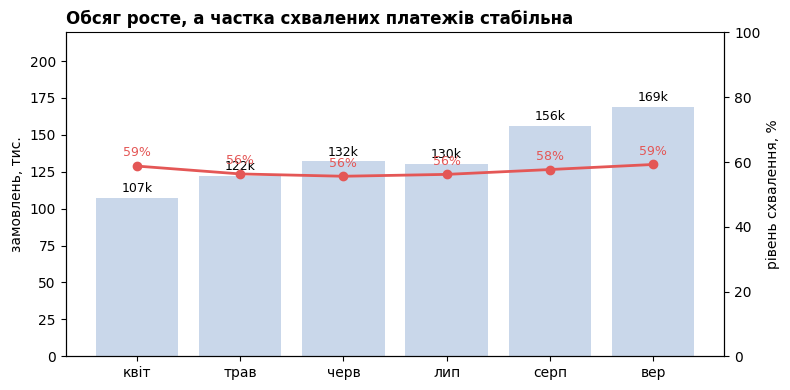

💡 За пів року обсяг зріс на 57%, а рівень схвалення тримається в межах 56–59%. Даних стає більше, тож перераховувати все щоразу буде все дорожче.

In [0]:
eda_monthly_trend()

### Чому платежі не проходять

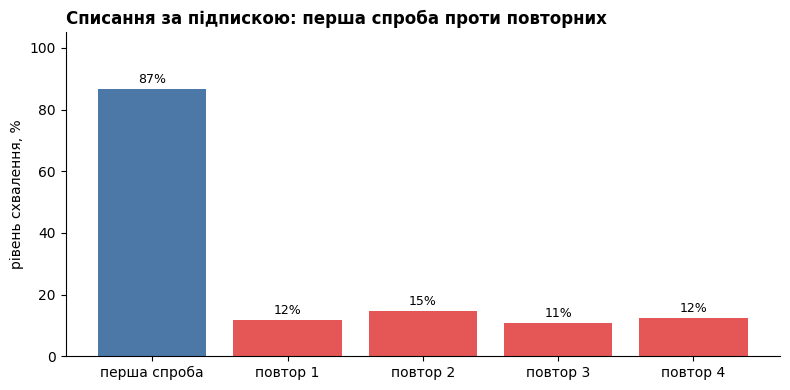

💡 Перша спроба проходить у 87% випадків, повторні лише в 11–15%. Повтори становлять 20% усіх спроб, але дають лише 4% успішних платежів.

In [0]:
eda_retries()

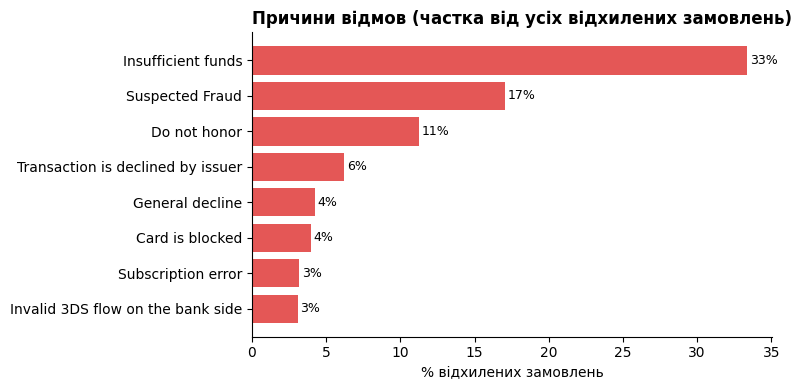

💡 Три причини дають 62% усіх відмов: «Insufficient funds», «Suspected Fraud», «Do not honor». Більшість відмов приходить від банку клієнта, а не через технічні збої.

In [0]:
eda_decline_reasons()

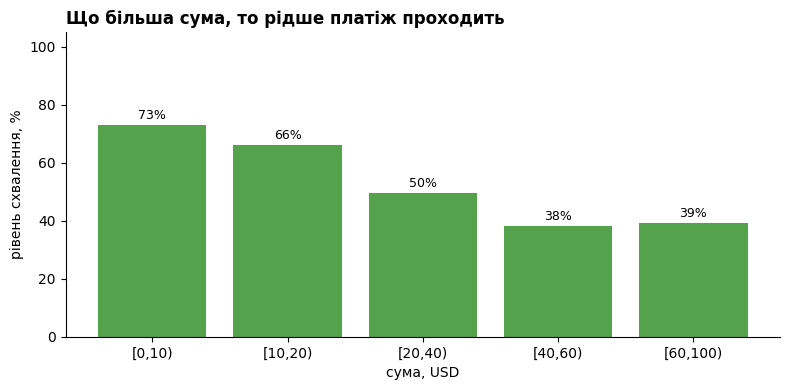

💡 Платежі до $10 схвалюються в 73% випадків, а на $40–60 лише в 38%.

In [0]:
eda_amount()

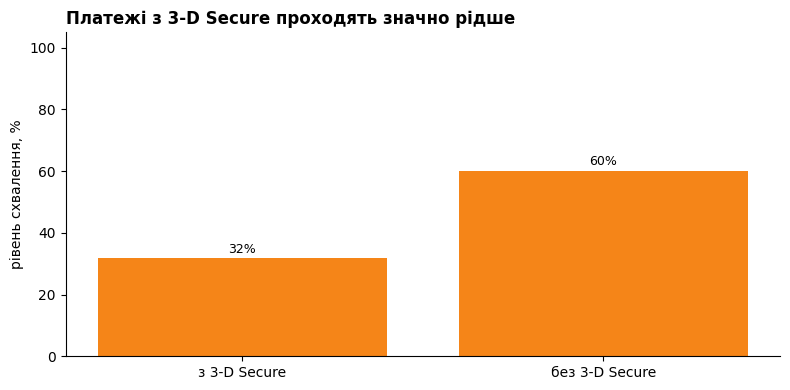

💡 Через 3-D Secure проходить лише 10% замовлень, і вони найважчі. Обережно з висновками: 3DS, найімовірніше, вмикають для ризикованіших платежів, тож це зв'язок, а не доказ причини.

In [0]:
eda_3ds()

### Хто платить

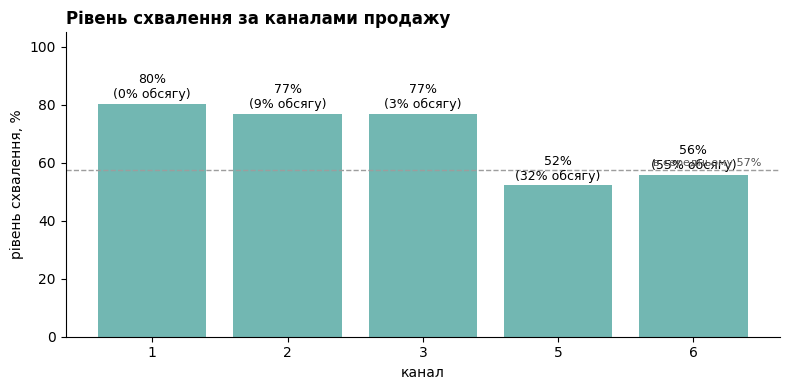

💡 Два найбільші канали (6, 5) дають 87% обсягу, і саме в них схвалення найнижче. Тому моніторимо кожен канал окремо, а не одне загальне число.

In [0]:
eda_channels()

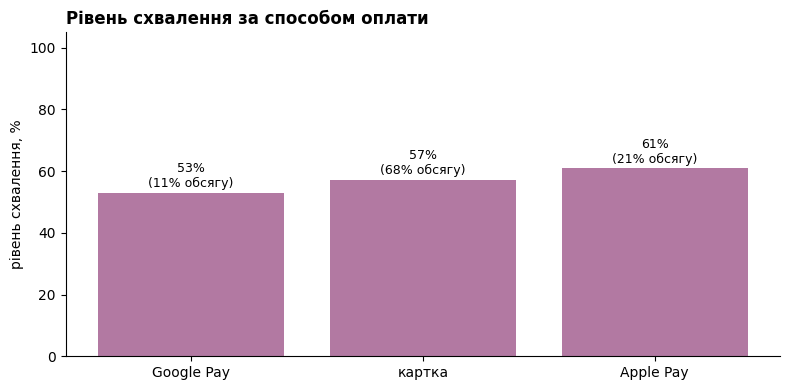

💡 Apple Pay проходить найкраще (61%), Google Pay найгірше (53%).

In [0]:
eda_payment_methods()

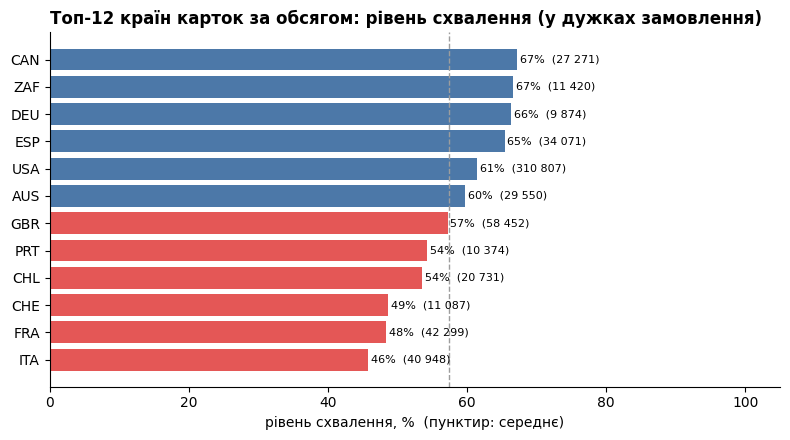

💡 Різниця між країнами велика: від 46% (ITA) до 67% (CAN). США дають 51% обсягу цього топу, тому збій там б'є найсильніше.

In [0]:
eda_countries()

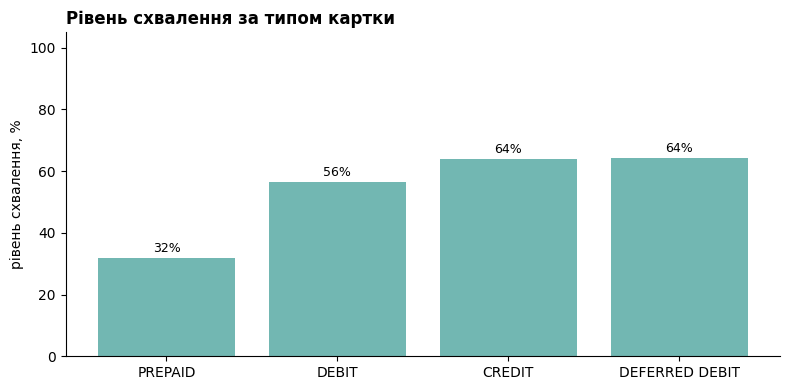

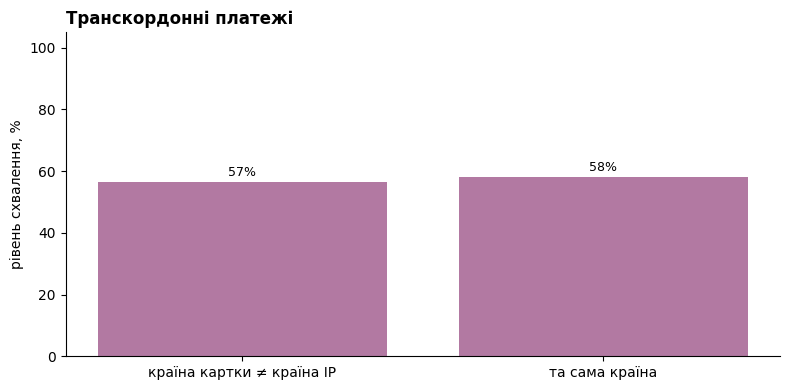

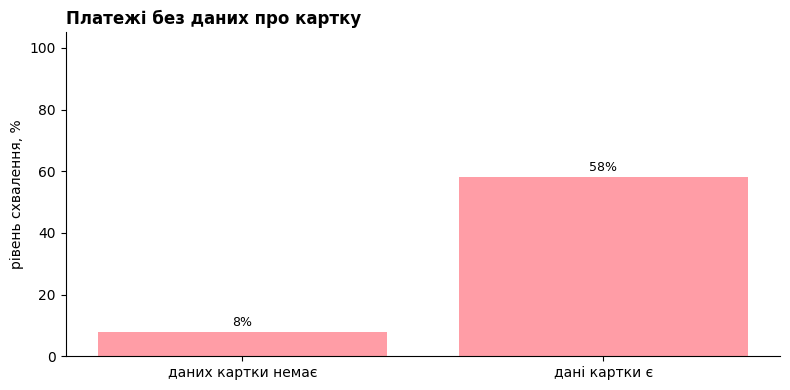

💡 Передплачені (prepaid) картки й транскордонні платежі відхиляються частіше, а платежі без даних картки майже ніколи не проходять (імовірно, картку так і не вдалося зчитати).

In [0]:
eda_quick_facts()

### Тижневий ритм: головне для логіки алертів

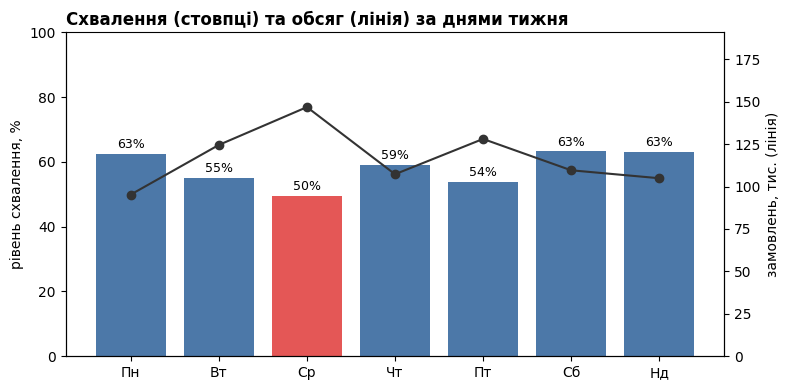

💡 У середу схвалюється лише 50% платежів, у вихідні понад 63%. Вівторок і середа мають найбільший обсяг (масові списання за підписками) і найнижче схвалення.

In [0]:
eda_weekday()

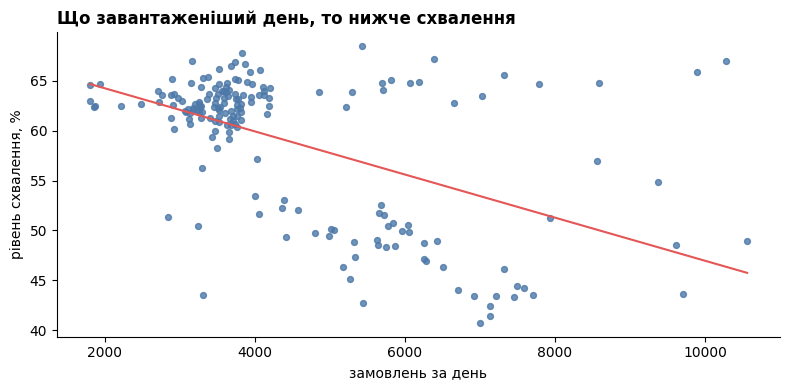

💡 Кореляція між обсягом за день і рівнем схвалення: -0.53. Висновок для моніторингу: порівнювати сьогодні з «останніми 7 днями» не можна, бо тоді щосереди будуть хибні тривоги. Наші алерти порівнюють ту саму годину того самого дня тижня за попередні 4 тижні.

In [0]:
eda_busy_days()

### Як історичні дані стають «потоком»

У CSV є лише дата, тому кожній події додано **синтетичний час доби**, а дані нарізано на **погодинні файли**.
Нова година даних = новий файл у папці `landing/`. Дати, денний і тижневий ритм справжні; розподіл подій усередині дня змодельований.

In [0]:
peek_staging()

Файл: payments_2023-04-01_00.csv


created_day,channel_id,order_type,payment_source,merchant_token_type,is_secured,bin_amount_usd,status,error_code,error_message,bank_issuer,card_brand,card_type,card_country,ip_country,invoice_number,retry_number,count_orders,count_emails,event_time
2023-04-01 00:00:00.000000,6,first,apple-pay,null,FALSE,"[20,40)",success,null,null,2393,MASTERCARD,DEBIT,AUS,AUS,0,0,2,2,2023-04-01 00:02:20
2023-04-01 00:00:00.000000,6,first,card,null,FALSE,"[20,40)",success,null,null,7524,VISA,CREDIT,USA,USA,0,0,1,1,2023-04-01 00:05:23
2023-04-01 00:00:00.000000,5,first,google-pay,null,FALSE,"[20,40)",fail,3.02,Insufficient funds,7962,VISA,DEBIT,IRL,IRL,null,no_subscription,1,1,2023-04-01 00:05:24
2023-04-01 00:00:00.000000,6,first,apple-pay,null,FALSE,"[0,10)",fail,0.01,General decline,6745,MASTERCARD,DEBIT,CZE,CZE,null,no_subscription,1,1,2023-04-01 00:06:07
2023-04-01 00:00:00.000000,2,token,card,recurring,FALSE,"[10,20)",success,null,null,7843,VISA,DEBIT,CAN,CAN,61,0,1,1,2023-04-01 00:06:40
2023-04-01 00:00:00.000000,5,token,card,recurring,FALSE,"[10,20)",fail,3.02,Insufficient funds,6535,MASTERCARD,CREDIT,CHL,CHL,1,1,1,1,2023-04-01 00:08:48
2023-04-01 00:00:00.000000,6,first,apple-pay,null,FALSE,"[40,60)",success,null,null,4043,MASTERCARD,CREDIT,USA,USA,0,0,5,5,2023-04-01 00:09:57
2023-04-01 00:00:00.000000,2,token,card,recurring,FALSE,"[0,10)",success,null,null,8541,MASTERCARD,DEBIT,SGP,SGP,47,0,1,1,2023-04-01 00:10:29
2023-04-01 00:00:00.000000,6,first,card,null,TRUE,"[20,40)",fail,3.10,Suspected Fraud,3623,VISA,CREDIT,USA,USA,null,no_subscription,3,1,2023-04-01 00:14:31
2023-04-01 00:00:00.000000,3,token,card,recurring,FALSE,"[0,10)",success,null,null,6797,VISA,DEBIT,USA,USA,45,0,1,1,2023-04-01 00:14:39


## 2 · Як це роблять batch: нічний звіт

**Сценарій.** Четвер, 14.09.2023. О 10:00 у каналі 6 частина платежів карток із США починає відхилятися з кодом «Do not honor»
(так виглядає, наприклад, збій у еквайра). Збій триває до 16:00. *Інцидент змодельований, решта даних справжня.*

Типова компанія без streaming рахує звіт **раз на добу**: о 06:00 batch-задача перечитує всю історію і показує вчорашній день.

In [0]:
show_nightly_report(run_nightly_batch())

(результат нічного запуску взято з кешу: 52 с, 3 960 файлів)


сегмент,замовлень,схвалення,норма,падіння
канал 6 · USA,1 687,56.3%,72.7%,−16.4 п.п.


**А якщо запускати batch частіше, наприклад щогодини?** Кожен запуск усе одно перечитує всю історію, а вона росте.

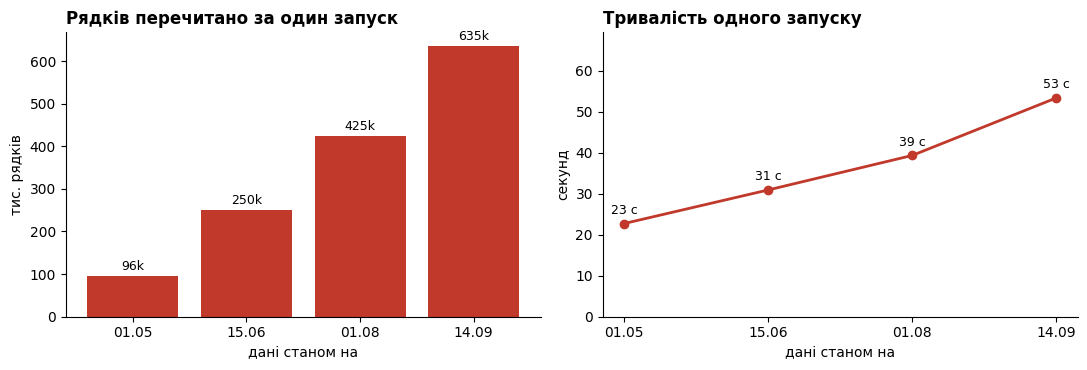

💡 Кожен batch-запуск перечитує всю історію. Щоб бачити дані свіжістю в 1 годину, його довелося б запускати 24 рази на добу: це 15 251 712 перечитаних рядків і близько 21 хв обчислень щодня, і з кожним днем більше.

In [0]:
plot_batch_cost()

## 3 · Streaming-пайплайн

```
landing/ ──► BRONZE ──► SILVER ──► GOLD ──► ALERTS
              сирі       чисті     схвалення   незвичні
              дані       дані      по годинах  падіння
                         └─► QUARANTINE
```

Ключові рядки коду (повністю в `03_pipeline`):

```python
spark.readStream.format("cloudFiles")          # Auto Loader: лише нові файли
  ...writeStream.foreachBatch(_ingest_batch)   # Bronze + Silver + Quarantine
  .trigger(availableNow=True)                  # обробити все нове і зупинитися

spark.readStream.table(silver)
  .withWatermark("event_time", "2 hours")      # що пізніше, ігноруємо
  .groupBy(window("event_time", "1 hour"), "channel_id", "card_country_grp")
  .writeStream.outputMode("update")            # оновлюємо лише змінені вікна (MERGE у Gold)
```

Історія до 14.09.2023, 08:00 уже пройшла через пайплайн (частина 0). Ось як він виглядає зараз:

In [0]:
show_pipeline_overview()

Landing файлів: 3 944 розмір: 88.4 MB погодинні CSV, які «прийшли» ➜ Bronze рядків: 635 488 колонок: 23 розмір: 5.8 MB · файлів: 3 Сирі дані як є, усі колонки текстом + звідки й коли прийшли ➜ Silver рядків: 629 615 колонок: 24 розмір: 5.9 MB · файлів: 3 Чисті дані з правильними типами + допоміжні колонки ➜ Gold рядків: 103 850 колонок: 8 розмір: 0.7 MB · файлів: 1 Замовлення, успішні, відхилені й схвалення за кожну годину й сегмент ➜ Alerts рядків: 0 колонок: 15 розмір: 0.0 MB · файлів: 0 Вікна, де схвалення незвично впало ↳ Quarantine рядків: 5 873 колонок: 24 розмір: 0.1 MB · файлів: 2 Биті рядки з оригінальними значеннями і причиною dq_reason

In [0]:
show_layer("bronze")

Bronze · workspace.payments_streaming.bronze_payments Сирі дані як є, усі колонки текстом + звідки й коли прийшли

колонка,тип
created_day,string
channel_id,string
order_type,string
payment_source,string
merchant_token_type,string
is_secured,string
bin_amount_usd,string
status,string
error_code,string
error_message,string


created_day,channel_id,order_type,payment_source,merchant_token_type,is_secured,bin_amount_usd,status,error_code,error_message,bank_issuer,card_brand,card_type,card_country,ip_country,invoice_number,retry_number,count_orders,count_emails,event_time,_rescued_data,_source_file,_ingested_at
2023-04-01 00:00:00.000000,6,first,apple-pay,null,FALSE,"[10,20)",success,null,null,2393,MASTERCARD,DEBIT,AUS,USA,0,0,1,1,2023-04-01 08:00:16,null,/Volumes/workspace/payments_streaming/data/landing/payments_2023-04-01_08.csv,2026-11-25T21:18:46.550Z
2023-04-01 00:00:00.000000,5,first,card,null,FALSE,"[40,60)",success,null,null,2307,MASTERCARD,DEBIT,GBR,GBR,0,0,1,1,2023-04-01 08:00:17,null,/Volumes/workspace/payments_streaming/data/landing/payments_2023-04-01_08.csv,2026-11-25T21:18:46.550Z
2023-04-01 00:00:00.000000,6,first,card,null,FALSE,"[0,10)",success,null,null,868,MASTERCARD,CREDIT,COL,COL,0,0,1,1,2023-04-01 08:01:00,null,/Volumes/workspace/payments_streaming/data/landing/payments_2023-04-01_08.csv,2026-11-25T21:18:46.550Z
2023-04-01 00:00:00.000000,2,token,card,recurring,FALSE,"[10,20)",success,null,null,1671,VISA,DEFERRED DEBIT,FRA,REU,68,0,1,1,2023-04-01 08:01:06,null,/Volumes/workspace/payments_streaming/data/landing/payments_2023-04-01_08.csv,2026-11-25T21:18:46.550Z
2023-04-01 00:00:00.000000,6,first,card,null,FALSE,"[20,40)",success,null,null,2483,MASTERCARD,CREDIT,NLD,NLD,0,0,1,1,2023-04-01 08:03:20,null,/Volumes/workspace/payments_streaming/data/landing/payments_2023-04-01_08.csv,2026-11-25T21:18:46.550Z


In [0]:
show_layer("silver")

Silver · workspace.payments_streaming.silver_payments Чисті дані з правильними типами + допоміжні колонки

колонка,тип
event_time,timestamp
channel_id,string
order_type,string
payment_source,string
merchant_token_type,string
is_secured,boolean
bin_amount_usd,string
status,string
error_code,string
error_message,string


event_time,channel_id,order_type,payment_source,merchant_token_type,is_secured,bin_amount_usd,status,error_code,error_message,bank_issuer,card_brand,card_type,card_country,card_country_grp,ip_country,country_mismatch,is_subscription_charge,retry_count,count_orders,count_emails,created_day,_source_file,_ingested_at
2023-04-01T08:00:16.000Z,6,first,apple-pay,null,false,"[10,20)",success,null,null,2393,MASTERCARD,DEBIT,AUS,AUS,USA,true,true,0,1,1,2023-04-01 00:00:00.000000,/Volumes/workspace/payments_streaming/data/landing/payments_2023-04-01_08.csv,2026-11-25T21:18:46.550Z
2023-04-01T08:00:17.000Z,5,first,card,null,false,"[40,60)",success,null,null,2307,MASTERCARD,DEBIT,GBR,GBR,GBR,false,true,0,1,1,2023-04-01 00:00:00.000000,/Volumes/workspace/payments_streaming/data/landing/payments_2023-04-01_08.csv,2026-11-25T21:18:46.550Z
2023-04-01T08:01:00.000Z,6,first,card,null,false,"[0,10)",success,null,null,868,MASTERCARD,CREDIT,COL,OTHER,COL,false,true,0,1,1,2023-04-01 00:00:00.000000,/Volumes/workspace/payments_streaming/data/landing/payments_2023-04-01_08.csv,2026-11-25T21:18:46.550Z
2023-04-01T08:01:06.000Z,2,token,card,recurring,false,"[10,20)",success,null,null,1671,VISA,DEFERRED DEBIT,FRA,FRA,REU,true,true,0,1,1,2023-04-01 00:00:00.000000,/Volumes/workspace/payments_streaming/data/landing/payments_2023-04-01_08.csv,2026-11-25T21:18:46.550Z
2023-04-01T08:03:20.000Z,6,first,card,null,false,"[20,40)",success,null,null,2483,MASTERCARD,CREDIT,NLD,OTHER,NLD,false,true,0,1,1,2023-04-01 00:00:00.000000,/Volumes/workspace/payments_streaming/data/landing/payments_2023-04-01_08.csv,2026-11-25T21:18:46.550Z


In [0]:
show_layer("gold")

Gold · workspace.payments_streaming.gold_hourly Замовлення, успішні, відхилені й схвалення за кожну годину й сегмент

колонка,тип
window_start,timestamp
window_end,timestamp
channel_id,string
card_country_grp,string
total_orders,bigint
success_orders,bigint
fail_orders,bigint
approval_rate,double


window_start,window_end,channel_id,card_country_grp,total_orders,success_orders,fail_orders,approval_rate
2023-09-06T20:00:00.000Z,2023-09-06T21:00:00.000Z,2,CHL,5,4,1,0.8
2023-09-06T13:00:00.000Z,2023-09-06T14:00:00.000Z,6,GBR,44,29,15,0.6590909090909091
2023-09-13T21:00:00.000Z,2023-09-13T22:00:00.000Z,2,ESP,2,2,0,1.0
2023-08-30T19:00:00.000Z,2023-08-30T20:00:00.000Z,5,GBR,8,7,1,0.875
2023-09-06T18:00:00.000Z,2023-09-06T19:00:00.000Z,1,OTHER,2,1,1,0.5


**Якість даних.** Рядки з датами, яких не існує (31 квітня, 31 червня, 31 вересня), не ламають потік: вони йдуть у карантин з оригінальними значеннями.

In [0]:
show_quarantine()

причина,рядків,замовлень
invalid_event_time,5865,7088
success_with_error_code,8,8


created_day,event_time,status,count_orders,dq_reason,_source_file
2023-06-31 00:00:00.000000,2023-06-31 06:00:20,success,1,invalid_event_time,/Volumes/workspace/payments_streaming/data/landing/payments_2023-06-30_06.csv
2023-06-31 00:00:00.000000,2023-06-31 06:01:27,success,1,invalid_event_time,/Volumes/workspace/payments_streaming/data/landing/payments_2023-06-30_06.csv
2023-06-31 00:00:00.000000,2023-06-31 06:01:35,success,1,invalid_event_time,/Volumes/workspace/payments_streaming/data/landing/payments_2023-06-30_06.csv
2023-06-31 00:00:00.000000,2023-06-31 06:03:00,fail,1,invalid_event_time,/Volumes/workspace/payments_streaming/data/landing/payments_2023-06-30_06.csv
2023-06-31 00:00:00.000000,2023-06-31 06:03:03,success,1,invalid_event_time,/Volumes/workspace/payments_streaming/data/landing/payments_2023-06-30_06.csv


**Це справді streaming?** Запустимо ті самі запити ще раз, без нових файлів.

In [0]:
rerun_without_new_data()

🔁 Повторний запуск без нових файлів: ingest прочитав 0 рядків, Gold 0 (12.2 с). Checkpoint пам'ятає, що вже оброблено. Batch на цьому місці перечитав би всю історію.

## 4 · Живий моніторинг

Зараз 14.09.2023, 08:00. Щогодини приходить нова година даних, пайплайн її обробляє, і система перевіряє кожен сегмент
(канал × країна картки) проти норми для цієї години цього дня тижня.

In [0]:
live_monitoring(hours=4)

▶️ Моніторинг запущено. Зараз 14.09.2023 08:00 , оновлення щогодини, сегменти: channel_id × card_country_grp.

🕐 14.09.2023 09:00 · прийшла година 08:00–09:00: 220 рядків · обробка 46.3 с · state: 82 рядків · канал 6 · картки USA: 73% · ✅ відхилень немає

🕐 14.09.2023 10:00 · прийшла година 09:00–10:00: 251 рядків · обробка 47.7 с · state: 88 рядків · канал 6 · картки USA: 71% · ✅ відхилень немає

🕐 14.09.2023 11:00 · прийшла година 10:00–11:00: 249 рядків · обробка 52.4 с · state: 90 рядків · канал 6 · картки USA: 25% · 🚨 нових алертів: 1

🚨 P1 · ALERT · ALR-20230914-10-6-USA 
 спрацював 14.09.2023 о 11:00 
 
 Різко впав рівень схвалення платежів 
 Сегмент: канал 6 · картки USA · година 10:00–11:00 
 
 Схвалення зараз 25% 
 Норма для цієї години 75% 
 Падіння −50 п.п. 
 Замовлень за годину 92 
 Втрачено платежів (оцінка) 46 
 Під загрозою ≈ $1 255 
 
 
 Головні причини відмов: Do not honor — 77% відмов Insufficient funds — 16% відмов Suspected Fraud — 8% відмов 
 Що робити зараз: 
 Перевірити статус еквайра та процесингу для цього сегмента. 
 Якщо збій на боці еквайра чи банку, перемкнути маршрутизацію на резервного еквайра. 
 Призупинити автоматичні повторні списання (retries) для сегмента: зараз вони лише додадуть відмов. 
 Повідомити account-менеджера мерчанта каналу 6. 
 
 
 📣 Сповіщено: #payments-oncall (Slack) · черговий інженер (PagerDuty) · відкрито інцидент INC-0914-6USA 
   (симуляція) · z-score = -11.0

🕐 14.09.2023 12:00 · прийшла година 11:00–12:00: 271 рядків · обробка 59.3 с · state: 91 рядків · канал 6 · картки USA: 17% · 🚨 нових алертів: 1

🔁 Інцидент триває (канал 6 · картки USA) · 11:00–12:00: схвалення 17% (норма 71%), ще ≈ 49 втрачених платежів. Оновлення додано в інцидент INC-0914-6USA, повторних сповіщень не надсилаємо.

[{'now': Timestamp('2023-09-14 09:00:00'),
  'files': ['payments_2023-09-14_08.csv'],
  'ingest': {'rows': 220,
   'batches': 1,
   'dropped_late': 0,
   'state_rows': 0,
   'state_mb': 0.0},
  'gold': {'rows': 0,
   'batches': 2,
   'dropped_late': 0,
   'state_rows': 82,
   'state_mb': 481.2266},
  'alerts': Empty DataFrame
  Columns: [alert_id, window_start, window_end, channel_id, card_country_grp, total_orders, approval_pct, baseline_pct, drop_pp, z_score, lost_orders_est, severity, detected_at, processed_at, status]
  Index: [],
  'seconds': 46.28669214248657},
 {'now': Timestamp('2023-09-14 10:00:00'),
  'files': ['payments_2023-09-14_09.csv'],
  'ingest': {'rows': 251,
   'batches': 1,
   'dropped_late': 0,
   'state_rows': 0,
   'state_mb': 0.0},
  'gold': {'rows': 0,
   'batches': 2,
   'dropped_late': 0,
   'state_rows': 88,
   'state_mb': 480.0302},
  'alerts': Empty DataFrame
  Columns: [alert_id, window_start, window_end, channel_id, card_country_grp, total_orders, approv

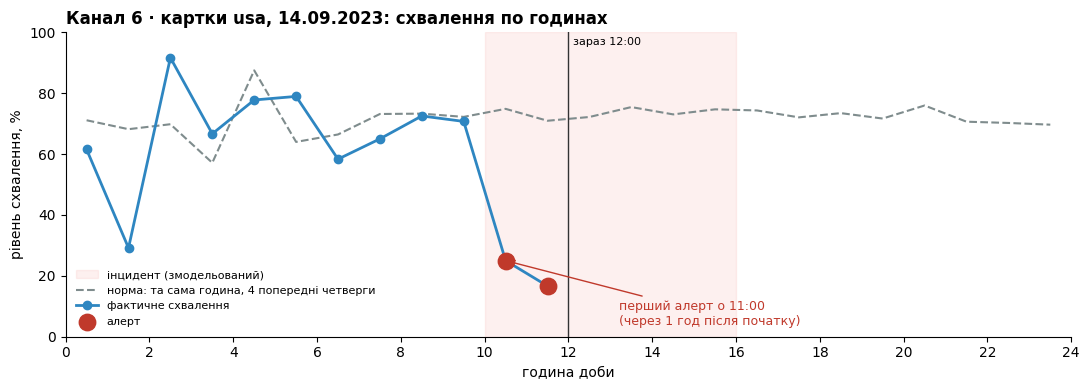

In [0]:
plot_incident_day()

Перемотаємо час до ранку наступного дня (саме тоді прийшов би нічний batch-звіт):

In [0]:
catch_up()

26/11/25 21:34:16 Listener thread still active, was not able to reconnect


⏩ Перемотали до 15.09.2023 08:00 : оброблено 0 годин, додано алертів: 4 (продовження того самого інциденту).

alert_id,window_start,approval_pct,baseline_pct,drop_pp,lost_orders_est,severity
ALR-20230914-12-6-USA,2023-09-14T12:00:00.000Z,22.5,72.2,49.7,44,P1
ALR-20230914-13-6-USA,2023-09-14T13:00:00.000Z,43.9,75.4,31.5,34,P1
ALR-20230914-14-6-USA,2023-09-14T14:00:00.000Z,35.9,73.0,37.1,29,P1
ALR-20230914-15-6-USA,2023-09-14T15:00:00.000Z,34.3,74.7,40.4,41,P1


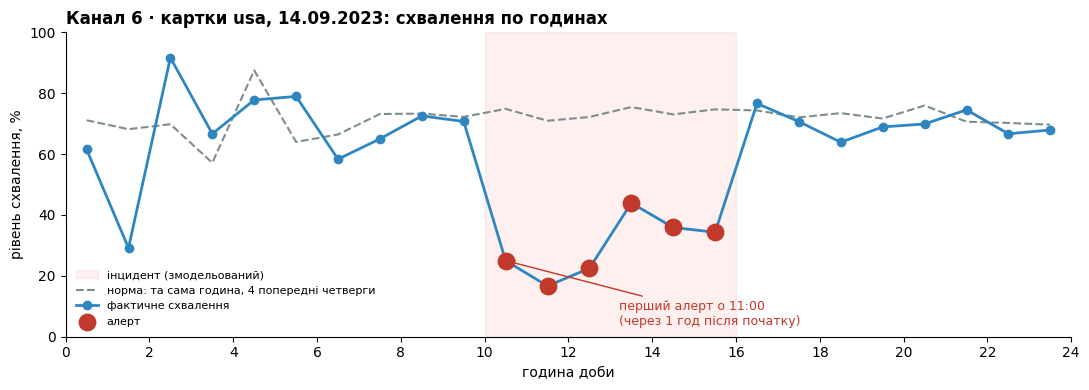

In [0]:
plot_incident_day()

## 5 · Batch проти streaming

### Скільки роботи робить кожне оновлення

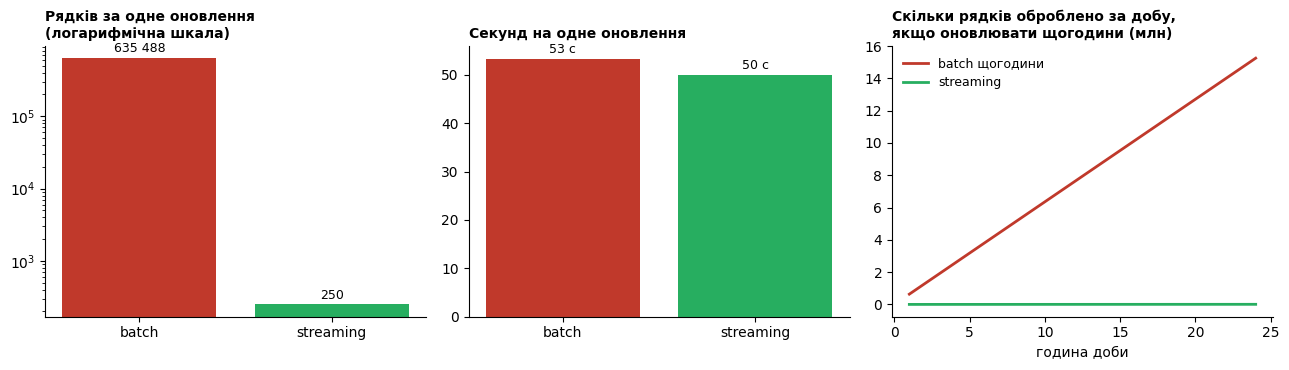

Batch: рядків за оновлення 635 488 перечитує всю історію Streaming: рядків за оновлення 250 лише нова година У скільки разів менше даних ×2 542 на кожному оновленні Batch: секунд 53 і росте разом з історією Streaming: секунд 50 майже не залежить від історії

ℹ️ На таких малих даних частину часу streaming-оновлення займає запуск самих запитів (фіксовані витрати Spark). Головна відмінність у тому, що обсяг роботи streaming не росте разом з історією, а batch росте лінійно.

In [0]:
plot_batch_vs_streaming()

In [0]:
show_processing_diagram()

Що відбувається всередині за одне оновлення 
 Batch · читає всі файли з початку історії, чистить і агрегує все заново 635 488 рядків 
 Streaming: нові дані · Auto Loader бере лише файли, яких ще не бачив (checkpoint) 250 рядків 
 Streaming: state у пам'яті · проміжні суми відкритих годинних вікон; старі вікна прибирає watermark 72 рядків

### Коли ми дізнаємося про проблему і скільки це коштує

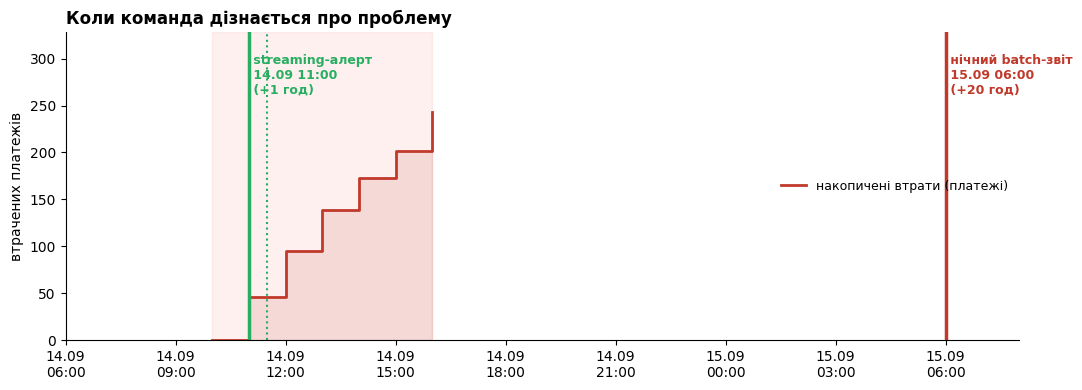

In [0]:
show_detection_timeline()

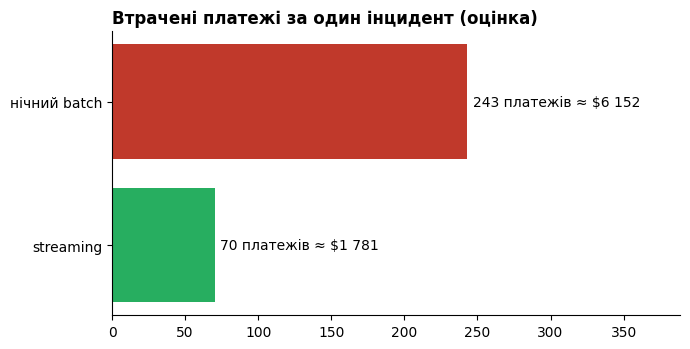

Streaming: сигнал через 1 год о 11:00 того ж дня Batch: сигнал через 20 год о 06:00 наступного дня Збережено платежів 173 71% втрат вдалося б уникнути Збережено грошей ≈ $4 372 середній чек ≈ $25

ℹ️ Як рахуємо: втрата за годину = замовлення × норма схвалення − фактично успішні. Припускаємо, що після сигналу команда за 30 хв перемикає трафік на резервного еквайра. Batch-звіт приходить, коли інцидент уже скінчився, тож усі втрати вже сталися. Це оцінка на змодельованому інциденті, а не фактичні гроші компанії.

In [0]:
show_business_impact()

## 6 · Додатково

### Пізні дані
Файл із квітневими платежами приходить лише у вересні. Watermark каже Gold, що ці вікна давно закриті.

In [0]:
demo_late_data()

📦 Надійшов файл late_payments_2023-04-03_12.csv (події 2023-04-03, тобто на місяці старші за watermark). Ingest прочитав 0 рядків і зберіг їх у Bronze та Silver. Gold відкинув як запізнілі: 25 рядків. Замовлень у Gold: 761 912 → 761 912 (без змін). Закриті вікна не переписуються.

In [0]:
show_alerts_table()

alert_id,severity,година,канал,країна,замовлень,схвалення_%,норма_%,падіння_пп,z_score,втрачено_оцінка,detected_at
ALR-20230914-15-6-USA,P1,2023-09-14T15:00:00.000Z,6,USA,102,34.3,74.7,40.4,-9.4,41,2023-09-14T16:00:00.000Z
ALR-20230914-14-6-USA,P1,2023-09-14T14:00:00.000Z,6,USA,78,35.9,73.0,37.1,-7.4,29,2023-09-14T15:00:00.000Z
ALR-20230914-13-6-USA,P1,2023-09-14T13:00:00.000Z,6,USA,107,43.9,75.4,31.5,-7.6,34,2023-09-14T14:00:00.000Z
ALR-20230914-12-6-USA,P1,2023-09-14T12:00:00.000Z,6,USA,89,22.5,72.2,49.7,-10.5,44,2023-09-14T13:00:00.000Z
ALR-20230914-11-6-USA,P1,2023-09-14T11:00:00.000Z,6,USA,90,16.7,71.0,54.3,-11.3,49,2023-09-14T12:00:00.000Z
ALR-20230914-10-6-USA,P1,2023-09-14T10:00:00.000Z,6,USA,92,25.0,74.9,49.9,-11.0,46,2023-09-14T11:00:00.000Z


### Висновки

* **Streaming обробляє лише нове**: checkpoint пам'ятає оброблені файли, state зберігає відкриті вікна, watermark відсікає запізнілі дані.
  Обсяг роботи на одне оновлення не росте з історією, а в batch росте.
* **Проблему видно за годину, а не наступного ранку**, тож команда встигає зреагувати, поки інцидент ще триває.
* **Чесні обмеження**: час доби змодельований, дані «приходять» цілими годинами, інцидент штучний, а `availableNow`
  запускається вручну (на serverless немає постійно ввімкнених тригерів). На кластері той самий код працює безперервно, змінюється лише тригер.
* **Застосування до інших даних**: змінити `CONFIG` у `00_config`, підготовку файлів у `01_data_prep` і правила якості в `transform_silver`.